# TP Visión por Computadora 2: lluvia semanal por píxel

**Objetivo:** con 14 imágenes diarias GOES-16 anteriores al corte, estimar para cada píxel si la precipitación total durante los siguientes 7 días alcanza **1 mm**. La salida es binaria; no se predice cantidad. El umbral es una definición de trabajo configurable.

Cada imagen tiene 16 bandas CMI. Una CNN con kernels 1×1, 3×3 y 5×5 procesa cada día con los mismos pesos; una ConvGRU aprende la evolución espacial, y un decoder produce un logit por píxel. Se comparan dos encoders: reducción mediante convolución con stride 2 y mediante MaxPool2d. El pooling reduce costo y amplía contexto, pero puede perder detalles finos.

El último GOES es del día D a las 15 UTC. La etiqueta comprende los siete días CPC D+1 a D+7, desde D+1 00 UTC hasta D+8 00 UTC. Hay un intervalo de 9 horas sin etiquetar. CPC es una estimación grillada basada en pluviómetros, no una medición puntual perfecta; evaluar solo píxeles válidos durante los siete días.

La descarga puede requerir varios cientos de MB. La preparación y el entrenamiento se ejecutan únicamente al correr sus celdas; se conservan intactos el TP estacional y sus resultados.

In [1]:
from pathlib import Path
import random, urllib.request
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from modelo_datos import leer_goes, CANALES_GOES, ConvGRUCell

BASE = Path.cwd()  # Ejecutar desde la raíz del repositorio
GOES = BASE / 'datos_crnn/goes_diario'
CPC = BASE / 'datos_crnn/cpc_diario'
GRILLA = BASE / 'cpc_grilla.nc'
HISTORIAL, HORIZONTE, UMBRAL_MM, PASO = 14, 7, 1.0, 7
EPOCAS, BATCH, TASA, SEED = 5, 2, 1e-3, 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('Dispositivo:', device)
assert GOES.is_dir() and GRILLA.is_file(), 'Abrí la notebook desde la raíz del repositorio y verificá los datos GOES.'

Dispositivo: mps


## 1. Datos diarios y particiones

Fuente: [NOAA PSL, CPC Global Daily Precipitation](https://psl.noaa.gov/data/gridded/data.cpc.globalprecip.html). Los archivos CPC contienen totales diarios en mm, grilla de 0,5° y coordenada temporal que indica el inicio del día. Se conservan las celdas faltantes como faltantes. La selección espacial usa las mismas coordenadas de la grilla de GOES, sin interpolar.

Las particiones son bloques temporales separados: se descarta toda ventana que cruce sus límites, tanto en sus entradas como en su horizonte de predicción. Las estadísticas de normalización se calculan exclusivamente con los días de entrenamiento.

In [2]:
rutas = {}
for ruta in sorted(GOES.glob('goes_*_15utc.nc')):
    fecha = pd.to_datetime(ruta.name[len('goes_'):len('goes_') + 10], errors='raise')
    if fecha in rutas: raise ValueError(f'Fecha GOES duplicada: {fecha}')
    rutas[fecha] = ruta
if not rutas: raise ValueError('No hay archivos GOES diarios.')
with xr.open_dataset(GRILLA) as grid:
    lat, lon = grid.lat.values.copy(), grid.lon.values.copy()
print(f'GOES: {len(rutas)} días entre {min(rutas).date()} y {max(rutas).date()}; grilla {len(lat)}×{len(lon)}')

# Bloques de ejemplo: adaptar las fechas si se amplía el dataset.
LIMITES = {
    'train': (pd.Timestamp('2018-01-01'), pd.Timestamp('2023-12-31')),
    'val':   (pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31')),
    'test':  (pd.Timestamp('2025-01-01'), pd.Timestamp('2025-12-31')),
}
assert all(LIMITES[a][1] < LIMITES[b][0] for a, b in [('train','val'), ('val','test')])

def construir_ventanas(rutas, limites, historial=HISTORIAL, horizonte=HORIZONTE, paso=PASO):
    ventanas = {}
    for nombre, (inicio, fin) in limites.items():
        ejemplos = []
        for dia in pd.date_range(inicio + pd.Timedelta(days=historial-1), fin - pd.Timedelta(days=horizonte), freq=f'{paso}D'):
            entrada = tuple(pd.date_range(end=dia, periods=historial, freq='D'))
            objetivo = tuple(pd.date_range(dia + pd.Timedelta(days=1), periods=horizonte, freq='D'))
            if all(d in rutas for d in entrada): ejemplos.append((entrada, objetivo))
        ventanas[nombre] = ejemplos
    return ventanas

ventanas = construir_ventanas(rutas, LIMITES)
for nombre, v in ventanas.items():
    print(nombre, len(v), 'ventanas', (f'{v[0][0][0].date()} → {v[-1][1][-1].date()}' if v else 'SIN VENTANAS'))
assert all(ventanas.values()), 'Revisá cobertura y límites: se requiere al menos una ventana en cada partición.'

GOES: 2639 días entre 2018-01-01 y 2025-04-07; grilla 70×46
train 287 ventanas 2018-01-08 → 2023-12-31
val 48 ventanas 2024-01-01 → 2024-12-29
test 12 ventanas 2025-01-01 → 2025-04-08


In [3]:
CPC.mkdir(parents=True, exist_ok=True)
anios = sorted({dia.year for v in ventanas.values() for _, objetivo in v for dia in objetivo})
for anio in anios:
    destino = CPC / f'precip.{anio}.nc'
    if not destino.exists():
        url = f'https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.{anio}.nc'
        temporal = destino.with_suffix('.nc.part')
        print('Descargando', url, flush=True)
        try:
            urllib.request.urlretrieve(url, temporal)
            with xr.open_dataset(temporal) as ds: assert 'precip' in ds and ds.sizes['time'] > 0
            temporal.replace(destino)
        finally:
            temporal.unlink(missing_ok=True)
print('Archivos CPC:', anios)

Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2018.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2019.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2020.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2021.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2022.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2023.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2024.nc
Descargando https://downloads.psl.noaa.gov/Datasets/cpc_global_precip/precip.2025.nc
Archivos CPC: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [4]:
def leer_cpc(rutas_anuales, lat, lon):
    partes = []
    for ruta in rutas_anuales:
        with xr.open_dataset(ruta) as ds:
            p = ds['precip']
            if p.attrs.get('units') != 'mm' or ds.time.attrs.get('coordinate_defines') != 'start':
                raise ValueError(f'Verificar unidades y convención temporal en {ruta}')
            p = p.assign_coords(lon=((p.lon + 180) % 360) - 180).sortby('lon').sortby('lat')
            # Las grillas son coincidentes: una selección exacta evita inventar valores.
            p = p.sel(lat=lat, lon=lon).transpose('time', 'lat', 'lon').load()
            partes.append(p)
    lluvia = xr.concat(partes, dim='time').sortby('time')
    fechas = pd.DatetimeIndex(lluvia.time.values)
    if fechas.has_duplicates or not (fechas == fechas.normalize()).all():
        raise ValueError('Fechas CPC duplicadas o no diarias a las 00 UTC.')
    valores = lluvia.values.astype(np.float32)
    valores[(valores < 0) | (valores > 1000)] = np.nan
    return dict(zip(fechas, valores))

lluvia = leer_cpc([CPC / f'precip.{a}.nc' for a in anios], lat, lon)
def etiqueta_semanal(fechas, lluvia, umbral=UMBRAL_MM):
    campos = np.stack([lluvia.get(d, np.full((len(lat), len(lon)), np.nan, np.float32)) for d in fechas])
    valida = np.isfinite(campos).all(axis=0)
    objetivo = np.where(valida, np.sum(campos, axis=0) >= umbral, 0).astype(np.float32)
    return objetivo[None], valida[None]

for nombre, lista in ventanas.items():
    n, positivos = 0, 0
    for _, fechas in lista:
        y, m = etiqueta_semanal(fechas, lluvia); n += m.sum(); positivos += y[m].sum()
    print(f'{nombre}: {n:,} píxeles válidos, lluvia >= {UMBRAL_MM} mm: {positivos/max(n,1):.1%}')
    assert n > 0, f'Sin etiquetas válidas en {nombre}'

train: 548,744 píxeles válidos, lluvia >= 1.0 mm: 60.6%
val: 91,776 píxeles válidos, lluvia >= 1.0 mm: 59.0%
test: 22,944 píxeles válidos, lluvia >= 1.0 mm: 74.6%


## 2. Normalización y dataset

Solo se usan las 16 bandas GOES; no se incluye precipitación como entrada. Los píxeles GOES faltantes se reemplazan por la media de su canal calculada en entrenamiento. Se requieren los 14 archivos diarios: si falta un día completo, se descarta la ventana.

In [5]:
dias_train = sorted({dia for entrada, _ in ventanas['train'] for dia in entrada})
suma = np.zeros(16, np.float64); suma2 = suma.copy(); cuenta = suma.copy()
for i, dia in enumerate(dias_train):
    x = leer_goes(rutas[dia], lat, lon).astype(np.float64)
    ok = np.isfinite(x)
    suma += np.where(ok, x, 0).sum(axis=(1,2))
    suma2 += np.where(ok, x*x, 0).sum(axis=(1,2))
    cuenta += ok.sum(axis=(1,2))
    if (i+1) % 300 == 0: print(f'Normalización: {i+1}/{len(dias_train)} días', flush=True)
if (cuenta == 0).any(): raise ValueError('Hay bandas sin datos válidos en train')
media = suma / cuenta
desvio = np.sqrt(np.maximum(suma2 / cuenta - media**2, 0))
if (desvio < 1e-8).any(): raise ValueError('Hay bandas constantes en train')
print('Bandas:', ', '.join(CANALES_GOES))

class Semanal(Dataset):
    def __init__(self, ejemplos): self.ejemplos = ejemplos
    def __len__(self): return len(self.ejemplos)
    def __getitem__(self, i):
        entrada, fechas = self.ejemplos[i]
        dias = []
        for dia in entrada:
            x = leer_goes(rutas[dia], lat, lon)
            x = np.where(np.isfinite(x), x, media[:,None,None])
            dias.append(((x-media[:,None,None])/desvio[:,None,None]).astype(np.float32))
        y, m = etiqueta_semanal(fechas, lluvia)
        return torch.from_numpy(np.stack(dias)), torch.from_numpy(y), torch.from_numpy(m)

datos = {k: Semanal(v) for k, v in ventanas.items()}
x0, y0, m0 = datos['train'][0]
print('X [días, bandas, alto, ancho]:', tuple(x0.shape), 'y/máscara:', tuple(y0.shape), 'válidos:', int(m0.sum()))
assert x0.shape[:2] == (HISTORIAL, 16) and torch.isfinite(x0).all()

Normalización: 300/2093 días
Normalización: 600/2093 días
Normalización: 900/2093 días
Normalización: 1200/2093 días
Normalización: 1500/2093 días
Normalización: 1800/2093 días
Bandas: CMI_C01, CMI_C02, CMI_C03, CMI_C04, CMI_C05, CMI_C06, CMI_C07, CMI_C08, CMI_C09, CMI_C10, CMI_C11, CMI_C12, CMI_C13, CMI_C14, CMI_C15, CMI_C16
X [días, bandas, alto, ancho]: (14, 16, 70, 46) y/máscara: (1, 70, 46) válidos: 1912


## 3. CNN multiescala + ConvGRU

Las dos variantes comparten ramas, cantidad de filtros, decoder y datos; cambia el mecanismo de reducción espacial. Se compara la validación antes de elegir el modelo y se evalúa test una sola vez. El pooling puede descartar información: no se supone que mejore el resultado.

In [6]:
class Modelo(nn.Module):
    def __init__(self, pooling=False):
        super().__init__()
        self.ramas = nn.ModuleList([nn.Sequential(nn.Conv2d(16, 8, k, padding=k//2), nn.ReLU()) for k in (1,3,5)])
        if pooling:
            self.encoder = nn.Sequential(nn.Conv2d(24,24,3,padding=1), nn.ReLU(), nn.MaxPool2d(2, ceil_mode=True),
                                         nn.Conv2d(24,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2, ceil_mode=True))
        else:
            self.encoder = nn.Sequential(nn.Conv2d(24,24,3,stride=2,padding=1), nn.ReLU(),
                                         nn.Conv2d(24,16,3,stride=2,padding=1), nn.ReLU())
        self.gru = ConvGRUCell(16,16)
        self.decoder = nn.Sequential(nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.Conv2d(32,16,1), nn.ReLU(), nn.Conv2d(16,1,1))
    def forward(self, x):
        h = None
        for dia in x.unbind(1):
            h = self.gru(self.encoder(torch.cat([r(dia) for r in self.ramas], dim=1)), h)
        h = F.interpolate(h, size=x.shape[-2:], mode='bilinear', align_corners=False)
        return self.decoder(h)

for pooling in (False, True):
    modelo = Modelo(pooling)
    with torch.no_grad(): out = modelo(x0[None])
    assert out.shape == y0[None].shape and torch.isfinite(out).all()
    print('pooling:', pooling, '| parámetros:', sum(p.numel() for p in modelo.parameters()), '| salida:', tuple(out.shape))

pooling: False | parámetros: 32241 | salida: (1, 1, 70, 46)
pooling: True | parámetros: 32241 | salida: (1, 1, 70, 46)


In [7]:
def evaluar(modelo, loader):
    modelo.eval(); logits, ys, masks = [], [], []
    with torch.no_grad():
        for x, y, m in loader:
            logits.append(modelo(x.to(device)).cpu()); ys.append(y); masks.append(m)
    return torch.cat(logits), torch.cat(ys), torch.cat(masks)

def metricas(logits, y, m, umbral=0.5):
    p = logits.sigmoid(); pv, yv = p[m], y[m]
    pred = pv >= umbral; real = yv.bool()
    tp = int((pred & real).sum()); fp = int((pred & ~real).sum()); fn = int((~pred & real).sum()); tn = int((~pred & ~real).sum())
    div = lambda a,b: a/b if b else float('nan')
    return {'BCE': F.binary_cross_entropy_with_logits(logits[m], yv).item(), 'Brier': ((pv-yv)**2).mean().item(),
            'precision': div(tp,tp+fp), 'recall': div(tp,tp+fn), 'F1': div(2*tp,2*tp+fp+fn),
            'IoU': div(tp,tp+fp+fn), 'accuracy': div(tp+tn,tp+tn+fp+fn), 'TP':tp, 'FP':fp, 'FN':fn, 'TN':tn}

def entrenar(pooling):
    torch.manual_seed(SEED)
    modelo = Modelo(pooling).to(device); optim = torch.optim.Adam(modelo.parameters(), lr=TASA)
    trainloader = DataLoader(datos['train'], batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    valloader = DataLoader(datos['val'], batch_size=BATCH, shuffle=False)
    mejor, estado, historia = float('inf'), None, []
    for epoca in range(1, EPOCAS+1):
        modelo.train(); total = n = 0
        for x, y, m in trainloader:
            x,y,m = x.to(device), y.to(device), m.to(device)
            if not m.any(): continue
            optim.zero_grad(set_to_none=True); logits = modelo(x)
            loss = F.binary_cross_entropy_with_logits(logits[m], y[m]); loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); optim.step()
            total += loss.item()*int(m.sum()); n += int(m.sum())
        lv,yv,mv = evaluar(modelo,valloader); met = metricas(lv,yv,mv); historia.append((total/n,met['BCE']))
        print(f"pooling={pooling} época {epoca}/{EPOCAS}: train BCE={total/n:.4f}, val BCE={met['BCE']:.4f}",flush=True)
        if met['BCE'] < mejor:
            mejor = met['BCE']; estado = {k:v.detach().cpu().clone() for k,v in modelo.state_dict().items()}
    modelo.load_state_dict(estado); return modelo, historia

# Entrenamiento deliberadamente corto; aumentar EPOCAS luego de revisar los datos.
modelos = {}
for pooling in (False, True): modelos[pooling] = entrenar(pooling)

pooling=False época 1/5: train BCE=0.6217, val BCE=0.5874
pooling=False época 2/5: train BCE=0.5603, val BCE=0.5413
pooling=False época 3/5: train BCE=0.5490, val BCE=0.5394
pooling=False época 4/5: train BCE=0.5385, val BCE=0.5396
pooling=False época 5/5: train BCE=0.5307, val BCE=0.5393
pooling=True época 1/5: train BCE=0.6128, val BCE=0.5757
pooling=True época 2/5: train BCE=0.5599, val BCE=0.5475
pooling=True época 3/5: train BCE=0.5497, val BCE=0.5329
pooling=True época 4/5: train BCE=0.5401, val BCE=0.5381
pooling=True época 5/5: train BCE=0.5309, val BCE=0.5388


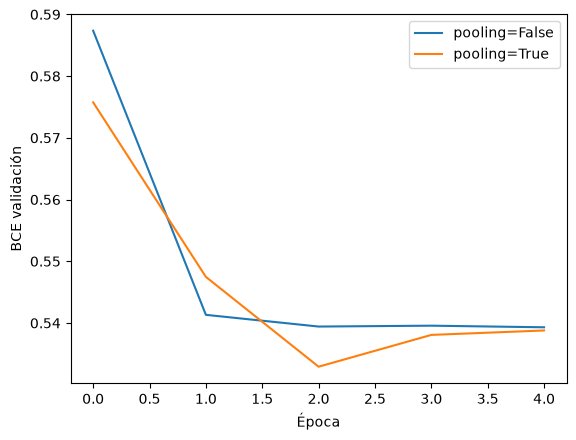

,BCE,Brier,precision,recall,F1,IoU,accuracy,TP,FP,FN,TN
False,0.539308,0.180750,0.727075,0.874940,0.794183,0.658627,0.732272,47406.0,17795.0,6776.0,19799.0
True,0.532922,0.178018,0.721383,0.899911,0.800818,0.667803,0.735715,48759.0,18832.0,5423.0,18762.0


Variante elegida por BCE de validación; pooling: True


In [8]:
val_loader = DataLoader(datos['val'], batch_size=BATCH, shuffle=False)
val_resultados = {}
for pooling, (modelo, historia) in modelos.items():
    logits, y_val, mask_val = evaluar(modelo, val_loader)
    val_resultados[pooling] = metricas(logits, y_val, mask_val)
    plt.plot([x[1] for x in historia], label=f'pooling={pooling}')
plt.xlabel('Época'); plt.ylabel('BCE validación'); plt.legend(); plt.show()
display(pd.DataFrame(val_resultados).T)
elegido = min(val_resultados, key=lambda k: val_resultados[k]['BCE'])
print('Variante elegida por BCE de validación; pooling:', elegido)

## 4. Evaluación final

Se informa la matriz de confusión y las métricas en test con umbral de probabilidad 0,5. También se comparan dos referencias constantes definidas con la proporción de lluvia de entrenamiento. Los píxeles y las semanas cercanas están correlacionados, por lo que no deben interpretarse como observaciones independientes.

,BCE,Brier,precision,recall,F1,IoU,accuracy,TP,FP,FN,TN
ConvGRU,0.427673,0.133475,0.855940,0.902653,0.878676,0.783606,0.814069,15448.0,2600.0,1666.0,3230.0
Frecuencia train,0.610475,0.209202,0.745903,1.000000,0.854461,0.745903,0.745903,17114.0,5830.0,0.0,0.0
Clase mayoritaria,5.081939,0.254097,0.745903,1.000000,0.854461,0.745903,0.745903,17114.0,5830.0,0.0,0.0


Prevalencia de train: 60.6%; pooling elegido: True


,inicio,BCE,Brier,precision,recall,F1,IoU,accuracy,TP,FP,FN,TN
0,2025-01-15,0.372040,0.111290,0.861128,0.955296,0.905771,0.827771,0.848849,1389,224,65,234
1,2025-01-22,0.343593,0.099093,0.913151,0.936983,0.924914,0.860316,0.875000,1472,140,99,201
2,2025-01-29,0.433598,0.134901,0.829478,0.942192,0.882250,0.789308,0.824791,1255,258,77,322
3,2025-02-05,0.578261,0.190430,0.779454,0.843046,0.810004,0.680678,0.733787,1085,307,202,318
4,2025-02-12,0.394780,0.125173,0.847887,0.889874,0.868374,0.767368,0.809100,1204,216,149,343


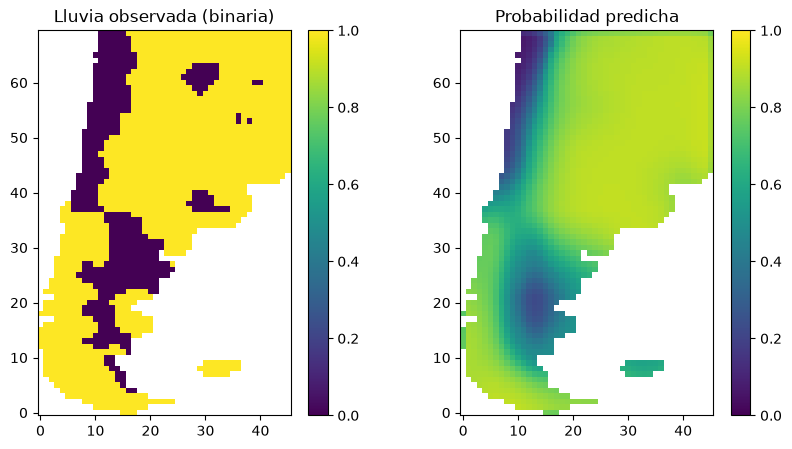

In [9]:
test_loader = DataLoader(datos['test'], batch_size=BATCH, shuffle=False)
logits, y_test, mask_test = evaluar(modelos[elegido][0], test_loader)
positivos = validos = 0
for _, fechas in ventanas['train']:
    y, m = etiqueta_semanal(fechas, lluvia); positivos += y[m].sum(); validos += m.sum()
prevalencia = float(positivos / validos)
p0 = float(np.clip(prevalencia, 1e-6, 1-1e-6))
base_logit = torch.full_like(logits, float(np.log(p0/(1-p0))))
mayoritaria = torch.full_like(logits, 20.0 if prevalencia >= .5 else -20.0)
resultados = {'ConvGRU': metricas(logits,y_test,mask_test), 'Frecuencia train': metricas(base_logit,y_test,mask_test), 'Clase mayoritaria': metricas(mayoritaria,y_test,mask_test)}
display(pd.DataFrame(resultados).T)
print(f'Prevalencia de train: {prevalencia:.1%}; pooling elegido: {elegido}')

# Métricas por semana: resumen descriptivo, no intervalos de confianza independientes.
semanas = []
for i, (_, fechas) in enumerate(ventanas['test']):
    m = mask_test[i:i+1]
    if m.any(): semanas.append({'inicio': fechas[0].date(), **metricas(logits[i:i+1], y_test[i:i+1], m)})
display(pd.DataFrame(semanas).head())

i = next(i for i in range(len(y_test)) if mask_test[i].any())
fig, axes = plt.subplots(1,2,figsize=(10,5))
for ax, arr, titulo in zip(axes, [y_test[i,0].numpy(), logits[i,0].sigmoid().numpy()], ['Lluvia observada (binaria)', 'Probabilidad predicha']):
    im = ax.imshow(np.where(mask_test[i,0].numpy(), arr, np.nan), origin='lower', vmin=0, vmax=1); ax.set_title(titulo); fig.colorbar(im, ax=ax)
plt.show()